In [4]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix

# ──── Paths ──────────────────────────────────────────────────────
TRAIN_FEATURES = '../data/processed/X_train.csv'
TRAIN_TARGET   = '../data/processed/y_train.csv'
TEST_FEATURES  = '../data/processed/X_test.csv'
TEST_TARGET    = '../data/processed/y_test.csv'

MODEL_LR  = '../models/base/logistic_regression.pkl'
MODEL_RF  = '../models/base/random_forest.pkl'
MODEL_GB  = '../models/base/gradient_boosting.pkl'

BASE_PROBS_CSV = '../notebooks/base_probabilities.csv'

# ──── Load processed data ────────────────────────────────────────
X_train = pd.read_csv(TRAIN_FEATURES)
y_train = pd.read_csv(TRAIN_TARGET)['TARGET']

X_test  = pd.read_csv(TEST_FEATURES)
y_test  = pd.read_csv(TEST_TARGET)['TARGET']

print("Training set shape:", X_train.shape)
print("Test set shape    :", X_test.shape)
print("Class distribution in train:", y_train.value_counts(normalize=True))

Training set shape: (246008, 199)
Test set shape    : (61503, 199)
Class distribution in train: TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


In [5]:
import pandas as pd
X_train = pd.read_csv('../data/processed/X_train.csv')
print(X_train.columns.tolist())
print("Number of columns:", len(X_train.columns))

['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '96', '97', '98', '99', '100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '110', '111', '112', '113', '114', '115', '116', '117', '118', '119', '120', '121', '122', '123', '124', '125', '126', '127', '128', '129', '130', '131', '132', '133', '134', '135', '136', '137', '138', '139', '140', '141', '142', '143', '144', '145', '146', '147', '148', '149', '150', '151', '152', '153', '154', '155', '156', '157', '15

In [6]:
# ──── Define and train base models ───────────────────────────────
models = {
    "LogisticRegression": LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        solver='saga',
        random_state=42
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=120,
        max_depth=12,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),
    "GradientBoosting": GradientBoostingClassifier(
        n_estimators=120,
        learning_rate=0.05,
        max_depth=5,
        random_state=42
    )
}

In [7]:
print("Number of features:", X_train.shape[1])
print("Shape of X_train:", X_train.shape)

Number of features: 199
Shape of X_train: (246008, 199)


In [8]:
base_probabilities = {}

for name, model in models.items():
    print(f"\nTraining {name} ...")
    model.fit(X_train, y_train)
    
    # Predict probabilities (probability of class 1 = default)
    probs_test = model.predict_proba(X_test)[:, 1]
    base_probabilities[name] = probs_test
    
    # Metrics
    auc = roc_auc_score(y_test, probs_test)
    print(f"{name} - ROC AUC: {auc:.4f}")
    
    # Classification report at default 0.5 threshold
    y_pred = (probs_test >= 0.5).astype(int)
    print(classification_report(y_test, y_pred))
    
    # Save model
    joblib.dump(model, f'../models/base/{name.lower().replace(" ", "_")}.pkl')
    print(f"Model saved: ../models/base/{name.lower().replace(' ', '_')}.pkl")


Training LogisticRegression ...


c:\Users\sharo\OneDrive\Documents\NMIMS\ML\credit-risk\venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  if n_iter_ == max_iter:


LogisticRegression - ROC AUC: 0.7460
              precision    recall  f1-score   support

           0       0.96      0.69      0.80     56538
           1       0.16      0.67      0.26      4965

    accuracy                           0.69     61503
   macro avg       0.56      0.68      0.53     61503
weighted avg       0.90      0.69      0.76     61503

Model saved: ../models/base/logisticregression.pkl

Training RandomForest ...
RandomForest - ROC AUC: 0.7390
              precision    recall  f1-score   support

           0       0.95      0.79      0.86     56538
           1       0.18      0.55      0.27      4965

    accuracy                           0.77     61503
   macro avg       0.57      0.67      0.57     61503
weighted avg       0.89      0.77      0.81     61503

Model saved: ../models/base/randomforest.pkl

Training GradientBoosting ...
GradientBoosting - ROC AUC: 0.7565
              precision    recall  f1-score   support

           0       0.92      1.00 

In [9]:
# ──── Save base probabilities for stacking ───────────────────────
pd.DataFrame(base_probabilities).to_csv(BASE_PROBS_CSV, index=False)
print(f"\nBase probabilities saved to: {BASE_PROBS_CSV}")


Base probabilities saved to: ../notebooks/base_probabilities.csv


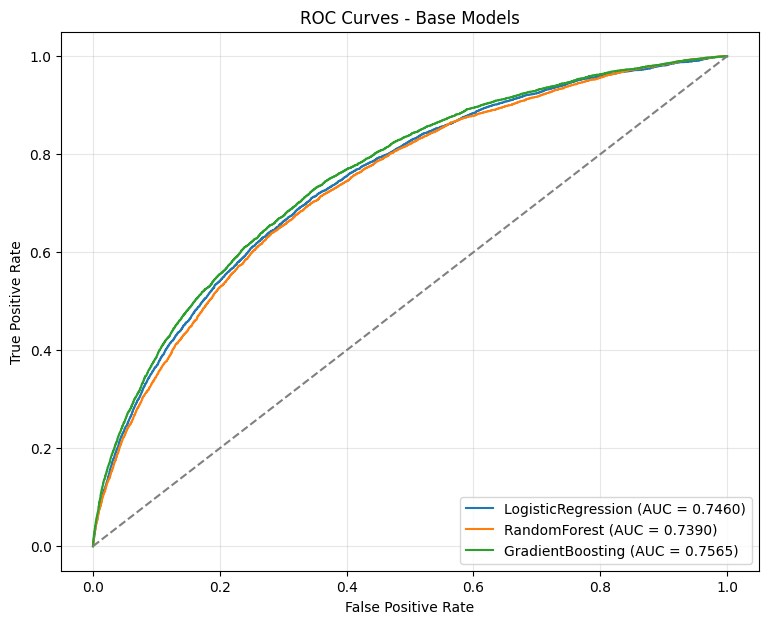

In [10]:
# ──── Quick ROC visualization ────────────────────────────────────
plt.figure(figsize=(9,7))

for name, probs in base_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})')

plt.plot([0,1], [0,1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Base Models')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.savefig('../reports/figures/03_base_models_roc.png', dpi=150, bbox_inches='tight')
plt.show()